# Análisis de sensibilidad — tamaño de detectores (10, 5 y 2 cm)

Este notebook **no ejecuta OpenGATE ni `sim.run()`**. Procesa los archivos `.root` y `.mhd` ya guardados para comparar los tres tamaños de puntuación. La función de cálculo de $\dot H^*(10)$ se reutiliza del notebook original, con su estimador de longitud de trayectoria, coeficientes de conversión y cálculo de incertidumbre.

**Antes de ejecutar:** revisa `N_PRIMARIES` y `N_PRIMARIES_NORMALIZATION` de cada prueba en la celda de configuración. Los valores propuestos de 10 millones son solo los valores sugeridos anteriormente, **no** valores verificados de tus corridas. Conserva la misma configuración de fuente y exposición usada en todas las simulaciones.

**Salida:** `output_sensibilidad/analisis_comparativo/`, sin modificar los resultados de cada prueba.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk
import uproot

BASE_DIR = Path.home() / "OpenGATE" / "pruebas_sensibilidad" / "output_sensibilidad"
ANALYSIS_DIR = BASE_DIR / "analisis_comparativo"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

# IMPORTANTE: sustituir por el número REAL de historias de cada simulación.
# El conteo de eventos del ROOT NO permite deducir directamente las historias primarias totales.
RUNS = {
    "10 cm": {"folder": "scoring_10cm", "size_cm": 10.0,
              "n_primaries": 10_000_000, "n_norm": 10_000_000},
    "5 cm":  {"folder": "scoring_5cm",  "size_cm": 5.0,
              "n_primaries": 10_000_000, "n_norm": 10_000_000},
    "2 cm":  {"folder": "scoring_2cm",  "size_cm": 2.0,
              "n_primaries": 10_000_000, "n_norm": 10_000_000},
}

# Condición experimental que figuraba en simulacion_final
EXPOSURE_TIME_S = 3.0
TUBE_CURRENT_MA = 240.6
PULSE_WIDTH_MS = 3.5
PULSE_RATE_HZ = 7.5
SPEKPY_KERMA_UGY_PER_MAS = 43.32
SPEKPY_REFERENCE_DISTANCE_CM = 115.0
IRP_SOURCE_DISTANCE_CM = 63.5
KA_R_MEASURED_MGY = None  # Mantener None si normalizaste usando SpekPy.

for label, run in RUNS.items():
    run["path"] = BASE_DIR / run["folder"]
    if run["n_primaries"] <= 1 or run["n_norm"] <= 0:
        raise ValueError(f"Conteo de historias no válido: {label}")
print("Carpetas de prueba:")
for label, run in RUNS.items():
    print(f"  {label}: {run['path']}")


Carpetas de prueba:
  10 cm: /home/xcpc/OpenGATE/pruebas_sensibilidad/output_sensibilidad/scoring_10cm
  5 cm: /home/xcpc/OpenGATE/pruebas_sensibilidad/output_sensibilidad/scoring_5cm
  2 cm: /home/xcpc/OpenGATE/pruebas_sensibilidad/output_sensibilidad/scoring_2cm


In [2]:
MEASUREMENT_POINTS = {'Medico_1': {'x_cm': 38.0, 'y_cm': -38.0, 'measured_msv_h': 2.738, 'u_measured_msv_h': 0.043}, 'Enfermero_1': {'x_cm': 117.0, 'y_cm': -57.0, 'measured_msv_h': 0.4355, 'u_measured_msv_h': 0.0112}, 'Tecnico_rayos_1': {'x_cm': 171.0, 'y_cm': 98.0, 'measured_msv_h': 0.176, 'u_measured_msv_h': 0.0081}, 'Tecnico_1': {'x_cm': -105.0, 'y_cm': -198.0, 'measured_msv_h': 0.1445, 'u_measured_msv_h': 0.0079}, 'Asistente': {'x_cm': 216.0, 'y_cm': 299.0, 'measured_msv_h': 0.0732, 'u_measured_msv_h': 0.0075}, 'Casa_comercial_1': {'x_cm': 20.0, 'y_cm': 289.0, 'measured_msv_h': 0.0112, 'u_measured_msv_h': 0.0074}, 'Casa_comercial_2': {'x_cm': 271.0, 'y_cm': 263.0, 'measured_msv_h': 0.04305, 'u_measured_msv_h': 0.0074}, 'B': {'x_cm': 257.0, 'y_cm': -65.0, 'measured_msv_h': 0.1915, 'u_measured_msv_h': 0.0082}, 'D': {'x_cm': 79.0, 'y_cm': -173.0, 'measured_msv_h': 0.261, 'u_measured_msv_h': 0.0089}, 'E': {'x_cm': -208.0, 'y_cm': -8.0, 'measured_msv_h': 0.1275, 'u_measured_msv_h': 0.0078}}

## 1. Comprobar archivos
Se necesitan, en cada prueba, un archivo `normalization/irp_air_dose.mhd` y diez archivos `main/<nombre>_hstar_phase_space.root`. Los `.mhd` deben conservar al lado el `.raw` correspondiente. Si faltan archivos, el notebook se detiene con una lista concreta.

In [3]:
missing = []
for label, run in RUNS.items():
    norm = run["path"] / "normalization" / "irp_air_dose.mhd"
    if not norm.is_file():
        missing.append(f"{label}: {norm}")
    for name in MEASUREMENT_POINTS:
        path = run["path"] / "main" / f"{name}_hstar_phase_space.root"
        if not path.is_file():
            missing.append(f"{label}: {path}")
if missing:
    raise FileNotFoundError("Archivos faltantes:\n" + "\n".join(missing))
print("Archivos presentes: 3 normalizaciones y 30 registros ROOT.")


Archivos presentes: 3 normalizaciones y 30 registros ROOT.


## 2. Coeficientes y estimador de $\dot H^*(10)$
Función copiada del código original del TFG para evitar recalcular usando fórmulas distintas. La incertidumbre Monte Carlo incluye implícitamente historias primarias con contribución cero. Las incertidumbres de normalización (IRP/SpekPy) **no** están incluidas en este estimador.

In [4]:
HSTAR_ENERGY_MEV = np.array([
    0.010,
    0.015,
    0.020,
    0.030,
    0.040,
    0.050,
    0.060,
    0.080,
    0.100,
    0.150,
    0.200,
    0.300,
    0.400,
    0.500,
    0.600,
    0.800,
    1.000,
])

HSTAR_COEFF_PSV_CM2 = np.array([
    0.061,
    0.83,
    1.05,
    0.81,
    0.64,
    0.55,
    0.51,
    0.53,
    0.61,
    0.89,
    1.20,
    1.80,
    2.38,
    2.93,
    3.44,
    4.38,
    5.20,
])

def hstar_coeff_from_energy_mev(energy_mev):

    energy_mev = np.asarray(
        energy_mev,
        dtype=float
    )

    coeff = np.full(
        energy_mev.shape,
        np.nan,
        dtype=float
    )

    valid = (
        (energy_mev >= HSTAR_ENERGY_MEV.min())
        &
        (energy_mev <= HSTAR_ENERGY_MEV.max())
    )

    coeff[valid] = np.exp(
        np.interp(
            np.log(
                energy_mev[valid]
            ),
            np.log(
                HSTAR_ENERGY_MEV
            ),
            np.log(
                HSTAR_COEFF_PSV_CM2
            )
        )
    )

    return coeff

def calculate_hstar10_point(
    root_path,
    n_primaries,
    equivalent_real_primaries,
    exposure_time_s,
    scoring_size_cm,
):

    volume_cm3 = (
        scoring_size_cm ** 3
    )

    # --------------------------------------------------------
    # LEER PHASE SPACE
    # --------------------------------------------------------

    with uproot.open(root_path) as f:

        tree = f[f.keys()[0]]

        arrays = tree.arrays(
            [
                "EventID",
                "ParticleName",
                "PreKineticEnergy",
                "StepLength",
            ],
            library="np"
        )

    event_id = arrays["EventID"]
    particle = arrays["ParticleName"]
    energy_mev = arrays["PreKineticEnergy"]
    step_length_mm = arrays["StepLength"]

    # --------------------------------------------------------
    # NORMALIZAR ParticleName A STRING
    # --------------------------------------------------------

    particle_str = np.array([
        (
            p.decode()
            if isinstance(p, bytes)
            else str(p)
        )
        for p in particle
    ])

    # --------------------------------------------------------
    # SOLO GAMMAS
    # --------------------------------------------------------

    gamma_mask = (
        particle_str == "gamma"
    )

    event_id = event_id[
        gamma_mask
    ]

    energy_mev = energy_mev[
        gamma_mask
    ]

    step_length_mm = step_length_mm[
        gamma_mask
    ]

    # --------------------------------------------------------
    # CONVERSIÓN mm -> cm
    # --------------------------------------------------------

    step_length_cm = (
        step_length_mm
        / 10.0
    )

    # --------------------------------------------------------
    # COEFICIENTES H*(10)
    # --------------------------------------------------------

    h_coeff = (
        hstar_coeff_from_energy_mev(
            energy_mev
        )
    )

    # --------------------------------------------------------
    # EVENTOS FUERA DE RANGO
    # --------------------------------------------------------

    valid = (
        np.isfinite(h_coeff)
        &
        np.isfinite(step_length_cm)
        &
        (step_length_cm > 0)
    )

    n_gamma_total = len(
        energy_mev
    )

    n_gamma_valid = np.sum(
        valid
    )

    fraction_valid = (
        n_gamma_valid
        / n_gamma_total
        if n_gamma_total > 0
        else np.nan
    )

    event_id = event_id[
        valid
    ]

    step_length_cm = (
        step_length_cm[
            valid
        ]
    )

    h_coeff = h_coeff[
        valid
    ]

    energy_valid_mev = (
        energy_mev[
            valid
        ]
    )

    # ========================================================
    # ESTIMADOR DE FLUENCIA POR LONGITUD DE TRAYECTORIA
    #
    # Phi = sum(L) / V
    #
    # Contribución:
    #
    # (cm / cm³) * (pSv cm²) = pSv
    # ========================================================

    hstar_step_pSv = (
        step_length_cm
        / volume_cm3
        * h_coeff
    )

    # ========================================================
    # SUMA POR HISTORIA MONTE CARLO
    # ========================================================

    unique_events, inverse = np.unique(
        event_id,
        return_inverse=True
    )

    hstar_per_event_pSv = np.bincount(
        inverse,
        weights=hstar_step_pSv
    )

    # --------------------------------------------------------
    # SUMA TOTAL DE LA CORRIDA
    # --------------------------------------------------------

    S1 = np.sum(
        hstar_per_event_pSv
    )

    S2 = np.sum(
        hstar_per_event_pSv ** 2
    )

    N = float(
        n_primaries
    )

    # ========================================================
    # H*(10) POR PRIMARIO
    # ========================================================

    hstar_per_primary_pSv = (
        S1 / N
    )

    # ========================================================
    # INCERTIDUMBRE ESTADÍSTICA
    #
    # Se incluyen implícitamente las historias con contribución 0.
    # ========================================================

    if N > 1 and S1 > 0:

        sample_variance = (
            S2
            - (S1 ** 2) / N
        ) / (
            N - 1
        )

        sample_variance = max(
            sample_variance,
            0.0
        )

        standard_error_mean = np.sqrt(
            sample_variance
            / N
        )

        relative_uncertainty = (
            standard_error_mean
            / hstar_per_primary_pSv
        )

    else:

        relative_uncertainty = np.nan

    # ========================================================
    # ESCALADO A LA EXPOSICIÓN REAL
    # ========================================================

    hstar_real_pSv = (
        hstar_per_primary_pSv
        * equivalent_real_primaries
    )

    # pSv -> mSv
    hstar_real_mSv = (
        hstar_real_pSv
        * 1e-9
    )

    # ========================================================
    # TASA H*(10)
    # ========================================================

    hstar_rate_mSv_h = (
        hstar_real_mSv
        * 3600.0
        / exposure_time_s
    )

    return {

        "Hstar_per_primary_pSv":
            hstar_per_primary_pSv,

        "Hstar_real_mSv":
            hstar_real_mSv,

        "Hstar_rate_mSv_h":
            hstar_rate_mSv_h,

        "u_MC_percent":
            relative_uncertainty
            * 100.0,

        "N_gamma_total":
            n_gamma_total,

        "N_gamma_valid":
            n_gamma_valid,

        "fraction_valid":
            fraction_valid,

        "energy_min_keV":
            (
                np.min(
                    energy_valid_mev
                )
                * 1000.0
                if len(
                    energy_valid_mev
                ) > 0
                else np.nan
            ),

        "energy_max_keV":
            (
                np.max(
                    energy_valid_mev
                )
                * 1000.0
                if len(
                    energy_valid_mev
                ) > 0
                else np.nan
            ),

        "N_events_nonzero":
            len(
                unique_events
            ),
    }

## 3. Recalcular cada prueba de forma independiente
La normalización se determina con el archivo IRP de cada carpeta. Se calcula la tasa $\dot H^*(10)$ por posición, diferencia relativa, incertidumbre estadística y diferencia normalizada exploratoria. La fuente absoluta del kerma permanece igual para las tres pruebas. Las observaciones experimentales se usan como referencia, no para ajustar parámetros.

In [5]:
mas = TUBE_CURRENT_MA * (PULSE_WIDTH_MS / 1000.0) * PULSE_RATE_HZ * EXPOSURE_TIME_S
ka_r_spekpy_mgy = (
    SPEKPY_KERMA_UGY_PER_MAS * mas
    * (SPEKPY_REFERENCE_DISTANCE_CM / IRP_SOURCE_DISTANCE_CM) ** 2
    / 1000.0
)
ka_r_reference_mgy = (
    ka_r_spekpy_mgy if KA_R_MEASURED_MGY is None else float(KA_R_MEASURED_MGY)
)

rows = []
norm_rows = []
for label, run in RUNS.items():
    irp_path = run["path"] / "normalization" / "irp_air_dose.mhd"
    irp_raw_gy = float(np.squeeze(sitk.GetArrayFromImage(sitk.ReadImage(str(irp_path)))))
    if not np.isfinite(irp_raw_gy) or irp_raw_gy <= 0:
        raise ValueError(f"Dosis IRP inválida en {label}: {irp_raw_gy}")
    irp_per_primary = irp_raw_gy / run["n_norm"]
    equivalent_primaries = (ka_r_reference_mgy * 1e-3) / irp_per_primary
    norm_rows.append({
        "Prueba": label,
        "N_principales": run["n_primaries"],
        "N_normalizacion": run["n_norm"],
        "IRP_Gy": irp_raw_gy,
        "IRP_Gy_por_primario": irp_per_primary,
        "Ka_ref_mGy": ka_r_reference_mgy,
        "Primarios_equivalentes": equivalent_primaries,
    })
    for name, pt in MEASUREMENT_POINTS.items():
        result = calculate_hstar10_point(
            root_path=run["path"] / "main" / f"{name}_hstar_phase_space.root",
            n_primaries=run["n_primaries"],
            equivalent_real_primaries=equivalent_primaries,
            exposure_time_s=EXPOSURE_TIME_S,
            scoring_size_cm=run["size_cm"],
        )
        mc = float(result["Hstar_rate_mSv_h"])
        u_mc_pct = float(result["u_MC_percent"])
        exp = float(pt["measured_msv_h"])
        u_exp = float(pt["u_measured_msv_h"])
        u_mc = abs(mc) * u_mc_pct / 100.0
        udiff = np.hypot(u_mc, u_exp)
        rows.append({
            "Prueba": label, "Tamano_cm": run["size_cm"], "Punto": name,
            "Experimental_mSv_h": exp, "u_exp_mSv_h": u_exp,
            "MC_mSv_h": mc, "u_MC_percent": u_mc_pct,
            "u_MC_mSv_h": u_mc,
            "Diferencia_percent": 100.0 * (mc - exp) / exp,
            "Cociente_MC_EXP": mc / exp,
            "z_exploratorio": (mc - exp) / udiff if udiff > 0 else np.nan,
            "N_eventos_contribuyen": result["N_events_nonzero"],
            "Fraccion_energia_valida": result["fraction_valid"],
            "N_gamma_total": result["N_gamma_total"],
            "N_gamma_valid": result["N_gamma_valid"],
        })

df = pd.DataFrame(rows)
df_norm = pd.DataFrame(norm_rows)
display(df_norm)
display(df[["Prueba", "Punto", "MC_mSv_h", "u_MC_percent", "Diferencia_percent", "z_exploratorio"]].round(3))
df.to_csv(ANALYSIS_DIR / "resultados_tres_tamanos.csv", index=False)
df_norm.to_csv(ANALYSIS_DIR / "normalizaciones_tres_tamanos.csv", index=False)
print("Archivos CSV exportados a", ANALYSIS_DIR)


,Prueba,N_principales,N_normalizacion,IRP_Gy,IRP_Gy_por_primario,Ka_ref_mGy,Primarios_equivalentes
0,10 cm,10000000,10000000,6.865879e-08,6.865879e-15,2.692048,3.920909e+11
1,5 cm,10000000,10000000,6.658097e-08,6.658097e-15,2.692048,4.043270e+11
2,2 cm,10000000,10000000,7.299854e-08,7.299854e-15,2.692048,3.687811e+11


,Prueba,Punto,MC_mSv_h,u_MC_percent,Diferencia_percent,z_exploratorio
0,10 cm,Medico_1,3.221,0.921,17.624,9.237
1,10 cm,Enfermero_1,0.722,1.950,65.842,15.933
2,10 cm,Tecnico_rayos_1,0.311,3.024,76.771,10.883
3,10 cm,Tecnico_1,0.064,6.430,-55.367,-8.967
4,10 cm,Asistente,0.072,6.505,-1.181,-0.098
5,10 cm,Casa_comercial_1,0.070,6.446,522.161,6.756
6,10 cm,Casa_comercial_2,0.074,6.244,71.543,3.532
7,10 cm,B,0.185,3.977,-3.335,-0.580
8,10 cm,D,0.229,3.495,-12.292,-2.681
9,10 cm,E,0.060,6.805,-52.644,-7.613


Archivos CSV exportados a /home/xcpc/OpenGATE/pruebas_sensibilidad/output_sensibilidad/analisis_comparativo


## 4. Sensibilidad respecto al detector de 10 cm
Se compara directamente $\dot H^*(10)$ entre configuraciones. Las diferencias relativas al detector de 10 cm no se deben confundir con diferencias relativas al experimento. La incertidumbre de diferencia entre simulaciones requiere covarianzas si las ejecuciones están correlacionadas; por eso este notebook muestra cambios y barras de incertidumbre individual, pero no declara compatibilidad estadística entre corridas.

In [6]:
base = df[df["Prueba"] == "10 cm"].set_index("Punto")
comparisons = []
for label in ["5 cm", "2 cm"]:
    alt = df[df["Prueba"] == label].set_index("Punto")
    for point in MEASUREMENT_POINTS:
        b = base.at[point, "MC_mSv_h"]
        a = alt.at[point, "MC_mSv_h"]
        comparisons.append({
            "Punto": point, "Prueba_comparada": label,
            "MC_10cm_mSv_h": b, "MC_comparada_mSv_h": a,
            "Cambio_vs_10cm_percent": 100 * (a - b) / b if b != 0 else np.nan,
            "Cambio_absoluto_mSv_h": a - b,
        })
df_sens = pd.DataFrame(comparisons)
display(df_sens.round(3))
df_sens.to_csv(ANALYSIS_DIR / "sensibilidad_respecto_10cm.csv", index=False)

summary_rows = []
for label, grp in df.groupby("Prueba", sort=False):
    summary_rows.append({
        "Prueba": label,
        "Mediana_abs_diferencia_exp_percent": grp["Diferencia_percent"].abs().median(),
        "Media_abs_diferencia_exp_percent": grp["Diferencia_percent"].abs().mean(),
        "Mediana_u_MC_percent": grp["u_MC_percent"].median(),
        "Max_u_MC_percent": grp["u_MC_percent"].max(),
        "Puntos_u_MC_menor_10percent": int((grp["u_MC_percent"] <= 10).sum()),
        "Puntos_abs_z_menor_igual_2": int((grp["z_exploratorio"].abs() <= 2).sum()),
        "Fraccion_gamma_valid_min": grp["Fraccion_energia_valida"].min(),
    })
df_summary = pd.DataFrame(summary_rows)
display(df_summary.round(3))
df_summary.to_csv(ANALYSIS_DIR / "resumen_sensibilidad.csv", index=False)


,Punto,Prueba_comparada,MC_10cm_mSv_h,MC_comparada_mSv_h,Cambio_vs_10cm_percent,Cambio_absoluto_mSv_h
0,Medico_1,5 cm,3.221,3.348,3.963,0.128
1,Enfermero_1,5 cm,0.722,0.710,-1.743,-0.013
2,Tecnico_rayos_1,5 cm,0.311,0.289,-7.189,-0.022
3,Tecnico_1,5 cm,0.064,0.081,25.540,0.016
4,Asistente,5 cm,0.072,0.078,7.257,0.005
5,Casa_comercial_1,5 cm,0.070,0.082,17.338,0.012
6,Casa_comercial_2,5 cm,0.074,0.074,-0.328,-0.000
7,B,5 cm,0.185,0.186,0.388,0.001
8,D,5 cm,0.229,0.248,8.256,0.019
9,E,5 cm,0.060,0.089,46.943,0.028


,Prueba,Mediana_abs_diferencia_exp_percent,Media_abs_diferencia_exp_percent,Mediana_u_MC_percent,Max_u_MC_percent,Puntos_u_MC_menor_10percent,Puntos_abs_z_menor_igual_2,Fraccion_gamma_valid_min
0,10 cm,54.006,87.876,5.110,6.805,10,2,1.0
1,5 cm,37.191,93.870,9.841,12.676,5,3,1.0
2,2 cm,40.545,62.944,25.638,40.114,2,5,1.0


## 5. Figuras para el TFG
Los gráficos se exportan a PDF (vectorial) y PNG (300 dpi). **Las líneas o bandas de ±2 en $z$ son orientativas:** faltan las incertidumbres sistemáticas de los parámetros del modelo.

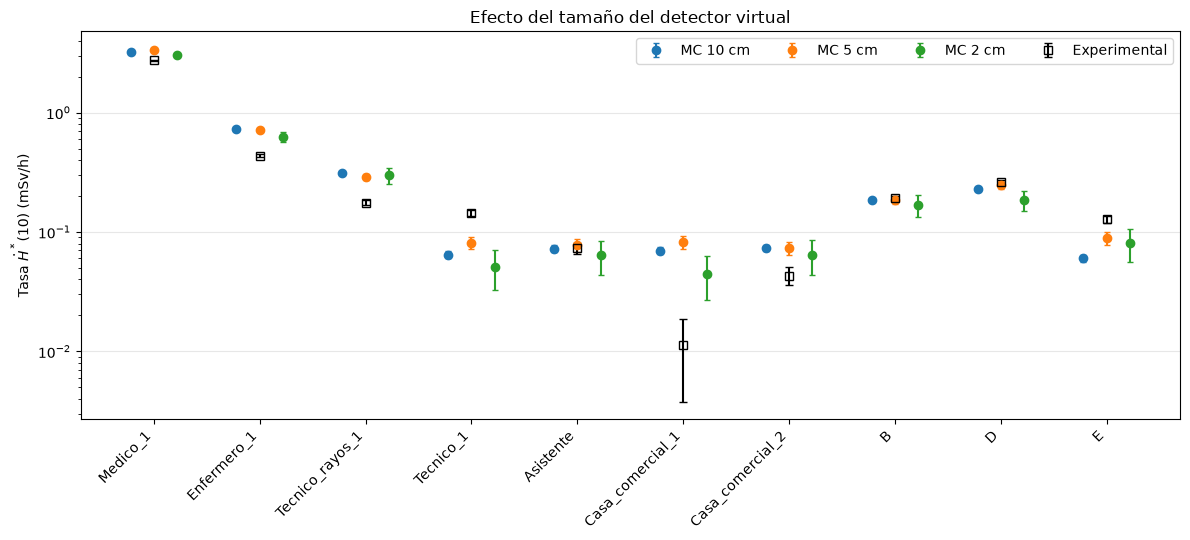

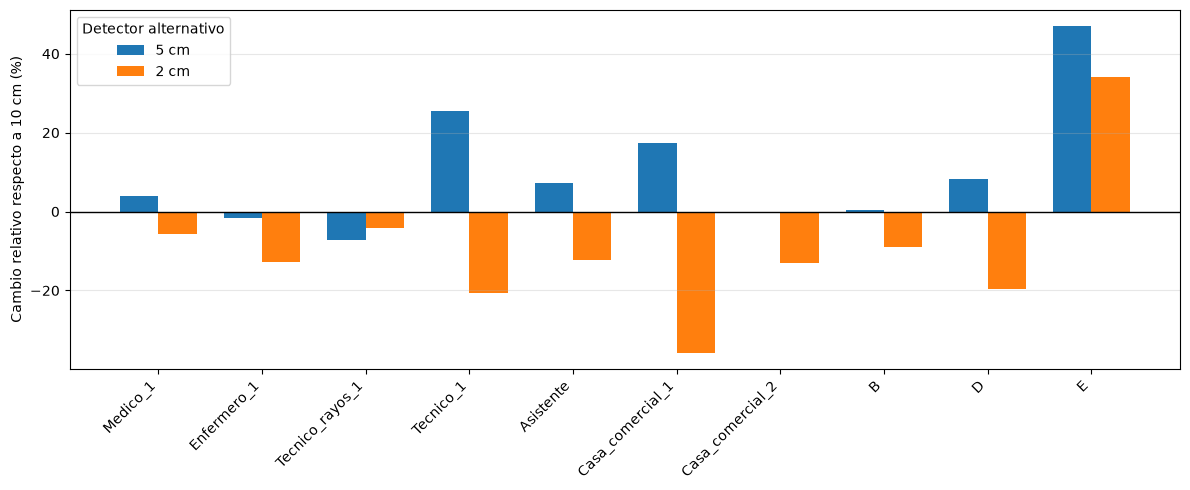

In [7]:
# Figura 1: H*(10) simulado y experimental, escala logarítmica.
order = list(MEASUREMENT_POINTS)
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(12, 5.5))
offsets = {"10 cm": -0.22, "5 cm": 0.0, "2 cm": 0.22}
for label in RUNS:
    sub = df[df["Prueba"] == label].set_index("Punto").loc[order]
    ax.errorbar(x + offsets[label], sub["MC_mSv_h"], yerr=sub["u_MC_mSv_h"],
                fmt="o", capsize=2, label=f"MC {label}")
exp = np.array([MEASUREMENT_POINTS[p]["measured_msv_h"] for p in order])
u_exp = np.array([MEASUREMENT_POINTS[p]["u_measured_msv_h"] for p in order])
ax.errorbar(x, exp, yerr=u_exp, fmt="s", color="black", mfc="none", capsize=3, label="Experimental")
ax.set_yscale("log")
ax.set_xticks(x, order, rotation=45, ha="right")
ax.set_ylabel(r"Tasa $\dot{H}^*(10)$ (mSv/h)")
ax.set_title("Efecto del tamaño del detector virtual")
ax.grid(axis="y", alpha=0.3)
ax.legend(ncol=4)
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "01_tasas_comparadas.pdf", bbox_inches="tight")
fig.savefig(ANALYSIS_DIR / "01_tasas_comparadas.png", dpi=300, bbox_inches="tight")
plt.show()

# Figura 2: cambio relativo frente al modelo de 10 cm.
fig, ax = plt.subplots(figsize=(12, 5))
width = 0.37
for off, label in [(-width / 2, "5 cm"), (width / 2, "2 cm")]:
    values = df_sens[df_sens["Prueba_comparada"] == label].set_index("Punto").loc[order]
    ax.bar(x + off, values["Cambio_vs_10cm_percent"], width=width, label=label)
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(x, order, rotation=45, ha="right")
ax.set_ylabel("Cambio relativo respecto a 10 cm (%)")
ax.legend(title="Detector alternativo")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "02_cambios_respecto_10cm.pdf", bbox_inches="tight")
fig.savefig(ANALYSIS_DIR / "02_cambios_respecto_10cm.png", dpi=300, bbox_inches="tight")
plt.show()


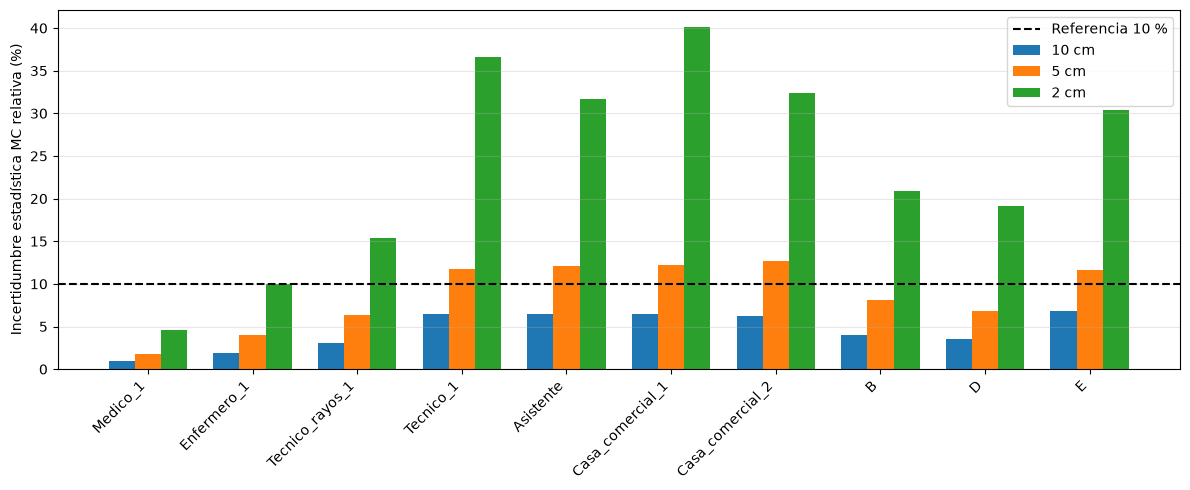

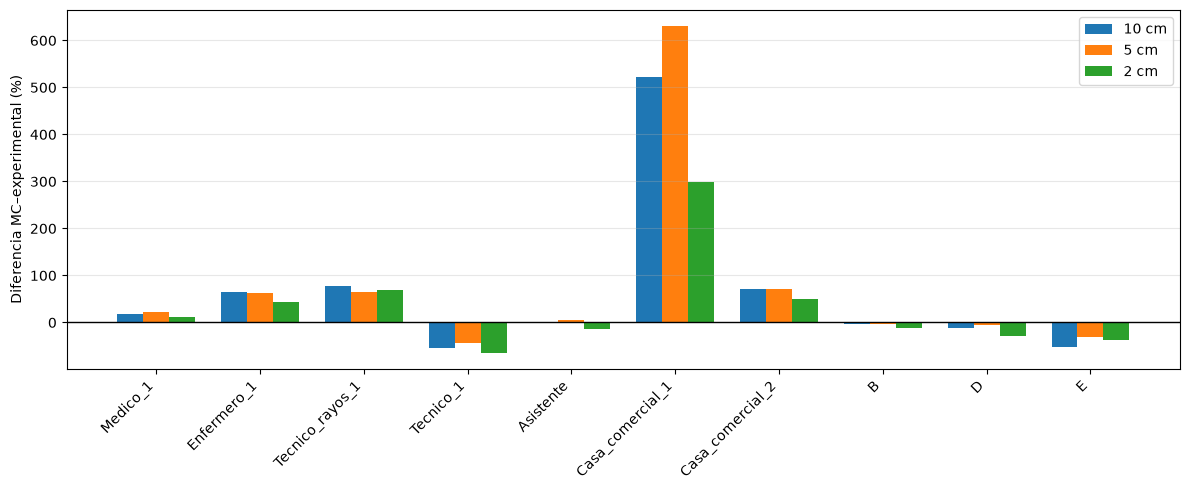

In [8]:
# Figura 3: incertidumbre estadística relativa de cada prueba.
fig, ax = plt.subplots(figsize=(12, 5))
width = 0.25
for offset, label in [(-width, "10 cm"), (0, "5 cm"), (width, "2 cm")]:
    sub = df[df["Prueba"] == label].set_index("Punto").loc[order]
    ax.bar(x + offset, sub["u_MC_percent"], width=width, label=label)
ax.axhline(10, color="black", linestyle="--", label="Referencia 10 %")
ax.set_xticks(x, order, rotation=45, ha="right")
ax.set_ylabel("Incertidumbre estadística MC relativa (%)")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "03_incertidumbre_MC.pdf", bbox_inches="tight")
fig.savefig(ANALYSIS_DIR / "03_incertidumbre_MC.png", dpi=300, bbox_inches="tight")
plt.show()

# Figura 4: diferencias respecto a los valores experimentales.
fig, ax = plt.subplots(figsize=(12, 5))
for offset, label in [(-width, "10 cm"), (0, "5 cm"), (width, "2 cm")]:
    sub = df[df["Prueba"] == label].set_index("Punto").loc[order]
    ax.bar(x + offset, sub["Diferencia_percent"], width=width, label=label)
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(x, order, rotation=45, ha="right")
ax.set_ylabel("Diferencia MC–experimental (%)")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "04_diferencias_experimentales.pdf", bbox_inches="tight")
fig.savefig(ANALYSIS_DIR / "04_diferencias_experimentales.png", dpi=300, bbox_inches="tight")
plt.show()


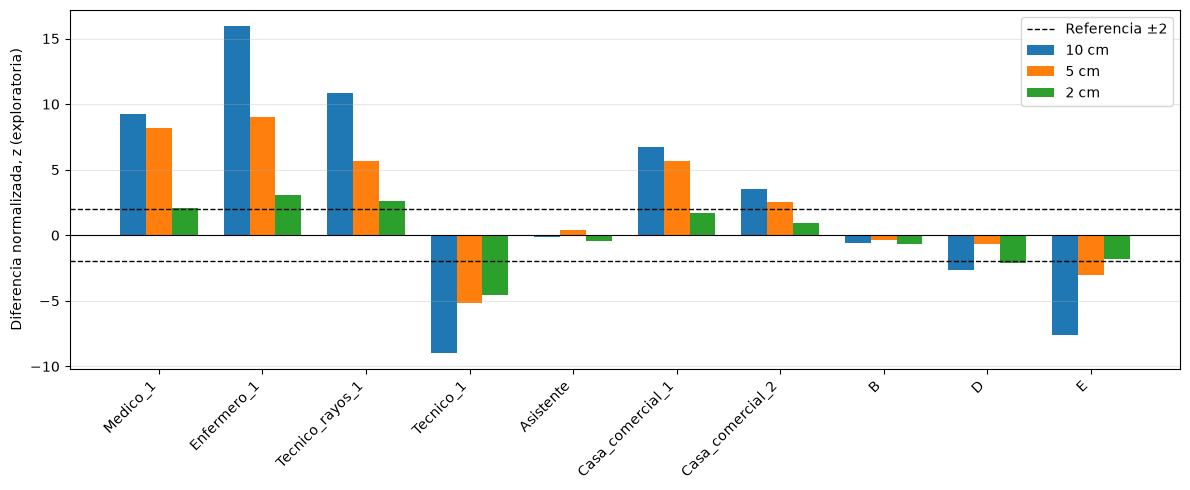

In [9]:
# Figura 5: diferencias normalizadas exploratorias.
fig, ax = plt.subplots(figsize=(12, 5))
for offset, label in [(-width, "10 cm"), (0, "5 cm"), (width, "2 cm")]:
    sub = df[df["Prueba"] == label].set_index("Punto").loc[order]
    ax.bar(x + offset, sub["z_exploratorio"], width=width, label=label)
ax.axhline(2, color="black", linestyle="--", linewidth=1, label="Referencia ±2")
ax.axhline(-2, color="black", linestyle="--", linewidth=1)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, order, rotation=45, ha="right")
ax.set_ylabel("Diferencia normalizada, z (exploratoria)")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "05_diferencias_normalizadas.pdf", bbox_inches="tight")
fig.savefig(ANALYSIS_DIR / "05_diferencias_normalizadas.png", dpi=300, bbox_inches="tight")
plt.show()
